# Identificação de Processos — Motor CC (Grupo 6)Sistemas Embarcados C213 — Projeto 1: Identificação do modelo FOPDT (k, τ, θ) da planta a partir do Ensaio da Curva de Reação, pelo método de Sundaresan, e comparação entre as respostas em Malha Aberta e Malha Fechada.

## 1. Instalação da biblioteca `control`

In [ ]:
!pip install control -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 30.0 MB/s eta 0:00:00


## 2. Carregamento do dataset (`Motor_G6.mat`)

In [ ]:
import scipy.io as sio
import numpy as np

d = sio.loadmat('Motor_G6.mat')

t = d['t'].ravel()
u = d['Degrau'].ravel()
y = d['Saida'].ravel()

print('Tamanho:', len(t))
print('t: de', t[0], 'até', t[-1])
print('Degrau: de', u[0], 'até', u[-1])
print('Saída (RPM) início:', y[:5])
print('Saída (RPM) fim:', y[-5:])

Tamanho: 601
t: de 0.0 até 60.0
Degrau: de 0.0 até 50.0
Saída (RPM) início: [ 1.5235854  -5.19992053  3.75225598  4.70282358 -9.75517594]
Saída (RPM) fim: [896.31658941 902.99595971 900.15450694 890.08448845 901.54927856]


## 3. Visualização dos dados brutos (Degrau x Saída)

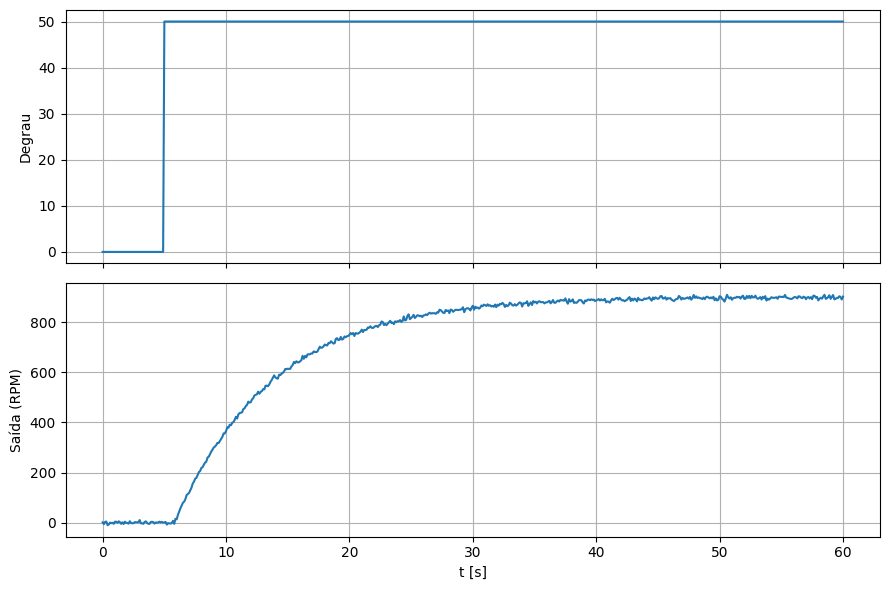

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 1, figsize=(9,6), sharex=True)
axs[0].plot(t, u)
axs[0].set_ylabel('Degrau')
axs[0].grid()

axs[1].plot(t, y)
axs[1].set_ylabel('Saída (RPM)')
axs[1].set_xlabel('t [s]')
axs[1].grid()

plt.tight_layout()
plt.savefig('dados_brutos_grupo6.png', dpi=150)
plt.show()

## 4. Identificação do instante do degrau (t0)

In [ ]:
idx_step = np.where(np.diff(u) != 0)[0][0]
t0_step = t[idx_step + 1]
print('Índice do degrau:', idx_step)
print('Instante do degrau (t0):', t0_step)

Índice do degrau: 49
Instante do degrau (t0): 5.0


## 5. Cálculo do ganho estático k = Δy/Δu

In [ ]:
y0 = y[:idx_step+1].mean()   # média da saída ANTES do degrau (deveria ser ~0)
y1 = y[-20:].mean()          # média da saída no final (regime permanente)

dy = y1 - y0
du = u[-1] - u[0]
k = dy / du

print('y0 (antes do degrau):', y0)
print('y1 (regime permanente):', y1)
print('Δy:', dy, '  Δu:', du)
print('k =', k)

y0 (antes do degrau): 0.45605515246505673
y1 (regime permanente): 898.0365191216958
Δy: 897.5804639692308   Δu: 50.0
k = 17.951609279384616


## 6. Escolha do método de identificação: Sundaresan

Usa-se Sundaresan pelo fato de o dataset possuir ruído.Encontram-se os valores de t para 35,3% do Δy e 85,3% do Δy.

In [ ]:
def t_at(frac):
    """Acha o instante em que y cruza frac*Δy acima de y0, por interpolação linear."""
    target = y0 + frac * dy
    idx = np.where(y >= target)[0][0]   # primeiro ponto que já passou do alvo
    tA, tB = t[idx-1], t[idx]
    yA, yB = y[idx-1], y[idx]
    return tA + (target - yA) / (yB - yA) * (tB - tA)

t1 = t_at(0.353) - t0_step   # referência relativa ao instante do degrau
t2 = t_at(0.853) - t0_step

print('t1 =', t1)
print('t2 =', t2)

t1 = 4.286531829657502
t2 = 15.9512098717811


## 7. Cálculo de τ e θ (Sundaresan)

In [ ]:
tau = (2/3) * (t2 - t1)
theta = 1.3*t1 - 0.29*t2

print('k     =', k)
print('tau   =', tau)
print('theta =', theta)

k     = 17.951609279384616
tau   = 7.776452028082398
theta = 0.9466405157382338


## 8. Construção do modelo FOPDT com aproximação de PadéMonta-se H(s) = k/(τs+1) em série com a aproximação de Padé de ordem 10 do atraso de transporte e^(-θs), seguindo a Seção 5.1 do enunciado.

In [ ]:
import control as cnt

H = cnt.tf([k], [tau, 1])          # planta de 1ª ordem: k / (tau*s + 1)

n_pade = 10                         # ordem da aproximação de Padé
num_pade, den_pade = cnt.pade(theta, n_pade)
H_atraso = cnt.tf(num_pade, den_pade)

H_modelo = cnt.series(H, H_atraso)  # junta planta + atraso em série
print(H_modelo)

<TransferFunction>: sys[2]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

           17.95 s^10 - 2086 s^9 + 1.19e+05 s^8 - 4.358e+06 s^7 + 1.128e+08 s^6 - 2.144e+09 s^5 + 3.02e+10 s^4 - 3.1e+11 s^3 + 2.21e+12 s^2 - 9.858e+12 s + 2.083e+13
  -----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  7.776 s^11 + 904.6 s^10 + 5.166e+04 s^9 + 1.894e+06 s^8 + 4.91e+07 s^7 + 9.352e+08 s^6 + 1.32e+10 s^5 + 1.36e+11 s^4 + 9.747e+11 s^3 + 4.393e+12 s^2 + 9.571e+12 s + 1.16e+12


## 9. Comparação: resposta real x modelo estimado

Simula-se a resposta ao degrau do modelo identificado e compara-se com os dados experimentais, para validar a identificação.

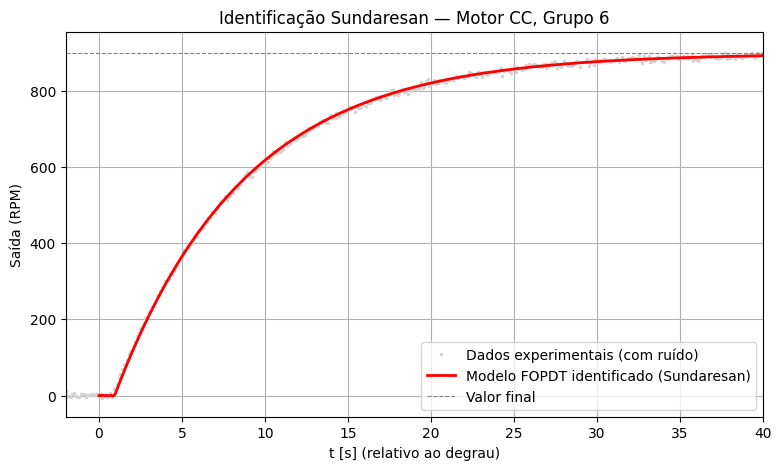

In [ ]:
t_sim = np.linspace(0, t[-1] - t0_step, 2000)  # tempo relativo ao degrau
t_resp, y_resp = cnt.step_response(H_modelo * du, t_sim)  # multiplica por du=50 (amplitude do degrau real)

plt.figure(figsize=(9,5))
plt.plot(t - t0_step, y, '.', color='lightgray', markersize=3, label='Dados experimentais (com ruído)')
plt.plot(t_resp, y_resp, 'r-', linewidth=2, label='Modelo FOPDT identificado (Sundaresan)')
plt.axhline(y1, color='gray', linestyle='--', linewidth=0.8, label='Valor final')
plt.xlabel('t [s] (relativo ao degrau)')
plt.ylabel('Saída (RPM)')
plt.title('Identificação Sundaresan — Motor CC, Grupo 6')
plt.legend()
plt.grid()
plt.xlim(-2, 40)
plt.savefig('identificacao_grupo6.png', dpi=150)
plt.show()

## 10. Malha Aberta x Malha Fechada (modelo identificado)

Compara-se a resposta ao degrau unitário do modelo em Malha Aberta com a resposta em Malha Fechada (realimentação unitária, sem controlador).

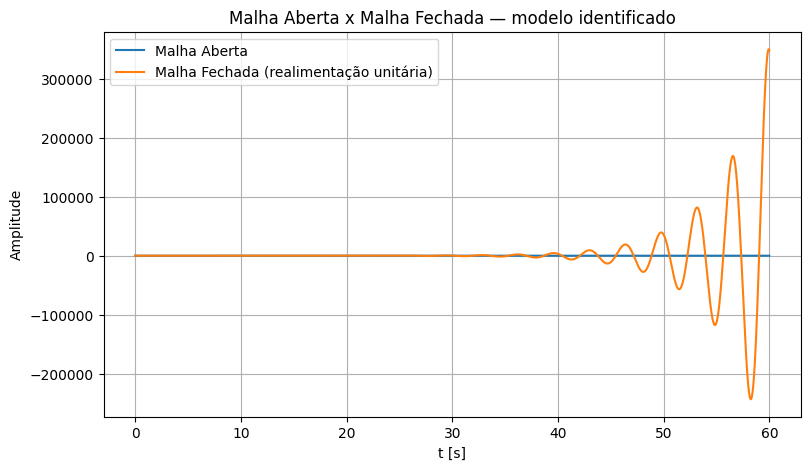

In [ ]:
H_fechada = cnt.feedback(H_modelo, 1)

t_sim2 = np.linspace(0, 60, 3000)
t_ma, y_ma = cnt.step_response(H_modelo, t_sim2)      # malha aberta
t_mf, y_mf = cnt.step_response(H_fechada, t_sim2)      # malha fechada

plt.figure(figsize=(9,5))
plt.plot(t_ma, y_ma, label='Malha Aberta')
plt.plot(t_mf, y_mf, label='Malha Fechada (realimentação unitária)')
plt.xlabel('t [s]')
plt.ylabel('Amplitude')
plt.title('Malha Aberta x Malha Fechada — modelo identificado')
plt.legend()
plt.grid()
plt.show()

## 11. Malha Aberta x Malha Fechada: gráficos separados

Separa-se os dois gráficos em subplots com escalas próprias, pois a Malha Fechada diverge (ganho estático alto + atraso de transporte tornam o sistema instável sem controlador), o que distorcia a escala do gráfico conjunto.

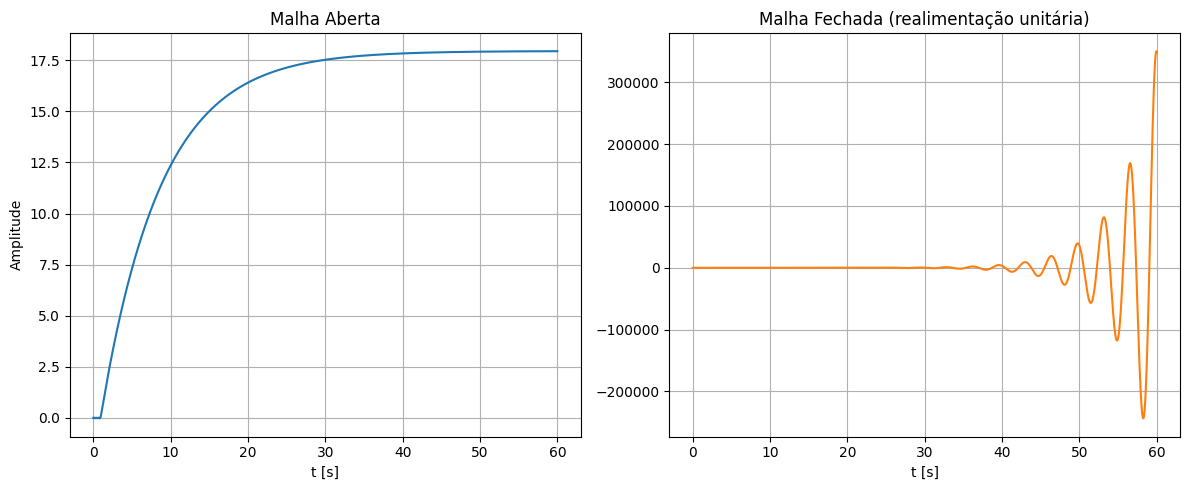

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12,5))

axs[0].plot(t_ma, y_ma, color='tab:blue')
axs[0].set_title('Malha Aberta')
axs[0].set_xlabel('t [s]'); axs[0].set_ylabel('Amplitude')
axs[0].grid()

axs[1].plot(t_mf, y_mf, color='tab:orange')
axs[1].set_title('Malha Fechada (realimentação unitária)')
axs[1].set_xlabel('t [s]')
axs[1].grid()

plt.tight_layout()
plt.savefig('malha_aberta_fechada_grupo6.png', dpi=150)
plt.show()